In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
# ==========================================
# Завдання 1. Підготовка даних
# ==========================================
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

100%|██████████| 170M/170M [06:36<00:00, 430kB/s] 


In [6]:
# ==========================================
# Завдання 2. Побудова та навчання CNN
# ==========================================
class PlantCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


model = PlantCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5
epoch_losses = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_losses.append(epoch_loss)
    print(f"Епоха [{epoch + 1}/{epochs}] — Loss: {epoch_loss:.4f}")

Епоха [1/5] — Loss: 1.3855
Епоха [2/5] — Loss: 1.0598
Епоха [3/5] — Loss: 0.9211
Епоха [4/5] — Loss: 0.8139
Епоха [5/5] — Loss: 0.7221


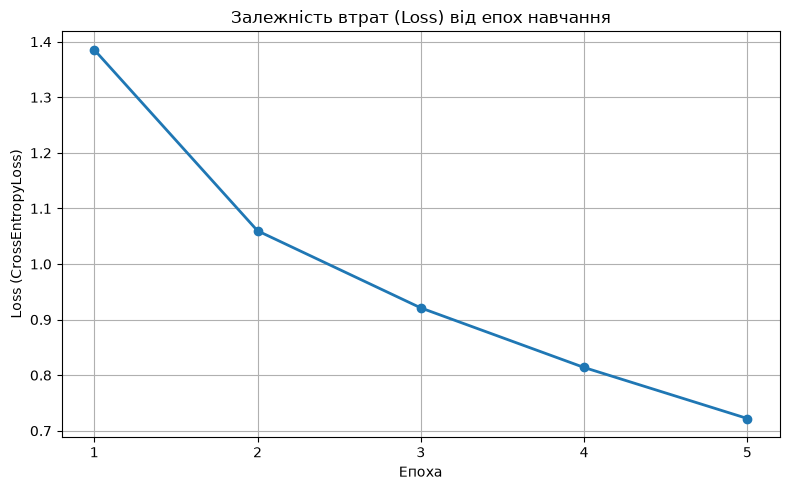

Модель збережено у файл plant_cnn.pth


In [7]:
# ==========================================
# Завдання 3. Візуалізація та збереження моделі
# ==========================================
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), epoch_losses, marker="o", linewidth=2)
plt.title("Залежність втрат (Loss) від епох навчання")
plt.xlabel("Епоха")
plt.ylabel("Loss (CrossEntropyLoss)")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.tight_layout()
plt.savefig("loss_plot.png")
plt.show()

torch.save(model.state_dict(), "plant_cnn.pth")
print("Модель збережено у файл plant_cnn.pth")

In [8]:
# ==========================================
# Завдання 4. Оцінка на тестовій вибірці
# ==========================================
model.eval()
test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

final_loss = test_loss / total
final_accuracy = 100.0 * correct / total

print("\n| Метрика | Значення |")
print("| :--- | :--- |")
print(f"| Accuracy | {final_accuracy:.2f}% |")
print(f"| Loss | {final_loss:.4f} |")


| Метрика | Значення |
| :--- | :--- |
| Accuracy | 65.98% |
| Loss | 1.0099 |
